# Tugas Praktikum - Klasifikasi Digit Tulisan Tangan (Dataset MNIST) dengan JST

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Kelas:** TI-3G  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---


## 1. Muat Dataset MNIST dan Pra-Pengolahan

Dataset MNIST terdiri dari 70.000 gambar hitam-putih digit angka tulisan tangan (0 s.d. 9) berukuran 28 × 28 piksel.
Data dibagi menjadi 60.000 data latih dan 10.000 data uji.
Langkah pra-pengolahan:
1. Normalisasi intensitas piksel dari rentang $[0, 255]$ ke rentang $[0.0, 1.0]$.
2. Mengubah label kelas target menjadi format *one-hot encoding* 10 kategori.

Dimensi X_train mentah: (60000, 28, 28), Jumlah label latih: (60000,)
Dimensi X_test mentah : (10000, 28, 28), Jumlah label uji  : (10000,)


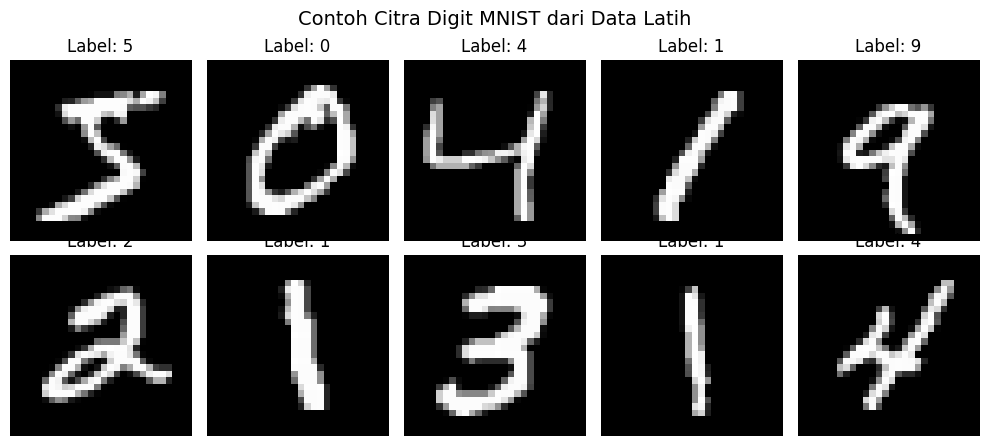

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix

tf.random.set_seed(42)
np.random.seed(42)

# 1. Load dataset MNIST
(X_train, y_train_raw), (X_test, y_test_raw) = mnist.load_data()
print(f"Dimensi X_train mentah: {X_train.shape}, Jumlah label latih: {y_train_raw.shape}")
print(f"Dimensi X_test mentah : {X_test.shape}, Jumlah label uji  : {y_test_raw.shape}")

# Normalisasi intensitas piksel (0-255 -> 0.0 - 1.0)
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# One-hot encoding label target
y_train = to_categorical(y_train_raw, 10)
y_test = to_categorical(y_test_raw, 10)

# Visualisasi 10 contoh digit pertama
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(f"Label: {y_train_raw[i]}")
    ax.axis('off')
plt.suptitle("Contoh Citra Digit MNIST dari Data Latih", fontsize=14)
plt.tight_layout()
plt.show()

## 2. Pembangunan Model Baseline JST (2 Hidden Layer)

Arsitektur awal:
- Lapisan `Flatten(input_shape=(28, 28))`: meratakan matriks citra 28 × 28 menjadi vektor 784 dimensi.
- `Hidden Layer 1`: 128 neuron, aktivasi ReLU
- `Hidden Layer 2`: 64 neuron, aktivasi ReLU
- `Output Layer`: 10 neuron, aktivasi Softmax (probabilitas kelas 0 s.d. 9)

In [2]:
# Model Baseline
model_baseline = Sequential([
    Flatten(input_shape=(28, 28), name='flatten_input'),
    Dense(128, activation='relu', name='hidden_1'),
    Dense(64, activation='relu', name='hidden_2'),
    Dense(10, activation='softmax', name='output_digits')
], name='MNIST_Baseline_128_64')

model_baseline.summary()

model_baseline.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

t_start = time.time()
history_base = model_baseline.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=64,
    verbose=1
)
time_base = time.time() - t_start

loss_base, acc_base = model_baseline.evaluate(X_test, y_test, verbose=0)
print(f"Hasil Model Baseline:")
print(f"  Waktu Pelatihan : {time_base:.2f} detik")
print(f"  Loss Data Uji   : {loss_base:.4f}")
print(f"  Akurasi Data Uji: {acc_base*100:.2f}%")

Model: "MNIST_Baseline_128_64"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_input (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_digits (Dense)           │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 109,386 (427.29 KB)
 Trainable params: 109,386 (427.29 KB)
 Non-trainable params: 0 (0.00 B)
Epoch 1/10

  

## 3. Eksperimen Komparasi Parameter Tambahan (Sesuai Tugas Praktikum)

Kita mengevaluasi 4 konfigurasi eksperimen terstruktur:
1. **Model 1 (Baseline):** 2 hidden layer `[128, 64]`, aktivasi **ReLU**
2. **Model 2 (Lebih Lebar):** 2 hidden layer `[256, 128]`, aktivasi **ReLU**
3. **Model 3 (Lebih Dalam):** 3 hidden layer `[256, 128, 64]`, aktivasi **ReLU**
4. **Model 4 (Aktivasi Sigmoid):** 2 hidden layer `[128, 64]`, aktivasi **Sigmoid**

In [3]:
configs = [
    {'name': 'Model 1: Baseline [128, 64] ReLU', 'layers': [128, 64], 'act': 'relu'},
    {'name': 'Model 2: Lebar [256, 128] ReLU', 'layers': [256, 128], 'act': 'relu'},
    {'name': 'Model 3: Dalam [256, 128, 64] ReLU', 'layers': [256, 128, 64], 'act': 'relu'},
    {'name': 'Model 4: Sigmoid [128, 64] Sigmoid', 'layers': [128, 64], 'act': 'sigmoid'},
]

histories = {}
comparison_table = []
trained_models = {}

for cfg in configs:
    print(f"Melatih {cfg['name']}...")
    tf.random.set_seed(42)
    np.random.seed(42)

    layers = [Flatten(input_shape=(28, 28))]
    for idx, n in enumerate(cfg['layers']):
        layers.append(Dense(n, activation=cfg['act'], name=f"{cfg['act']}_{idx+1}_{n}"))
    layers.append(Dense(10, activation='softmax', name='output_softmax'))

    m = Sequential(layers)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    t0 = time.time()
    h = m.fit(X_train, y_train, validation_split=0.1, epochs=10, batch_size=64, verbose=0)
    durasi = time.time() - t0

    loss_te, acc_te = m.evaluate(X_test, y_test, verbose=0)
    histories[cfg['name']] = h
    trained_models[cfg['name']] = m

    comparison_table.append({
        'Konfigurasi Model': cfg['name'],
        'Jumlah Layer': len(cfg['layers']),
        'Aktivasi': cfg['act'].upper(),
        'Total Parameter': m.count_params(),
        'Waktu Latih (s)': round(durasi, 2),
        'Loss Latih': round(h.history['loss'][-1], 4),
        'Akurasi Latih (%)': round(h.history['accuracy'][-1] * 100, 2),
        'Loss Uji': round(loss_te, 4),
        'Akurasi Uji (%)': round(acc_te * 100, 2)
    })

df_compare = pd.DataFrame(comparison_table)
print("\nTabel Perbandingan Hasil Eksperimen MNIST:")
print(df_compare.to_string(index=False))

Melatih Model 1: Baseline [128, 64] ReLU...
Melatih Model 2: Lebar [256, 128] ReLU...
Melatih Model 3: Dalam [256, 128, 64] ReLU...
Melatih Model 4: Sigmoid [128, 64] Sigmoid...

Tabel Perbandingan Hasil Eksperimen MNIST:
                 Konfigurasi Model  Jumlah Layer Aktivasi  Total Parameter  Waktu Latih (s)  Loss Latih  Akurasi Latih (%)  Loss Uji  Akurasi Uji (%)
  Model 1: Baseline [128, 64] ReLU             2     RELU           109386            16.61      0.0167              99.44    0.0968            97.50
    Model 2: Lebar [256, 128] ReLU             2     RELU           235146            24.53      0.0129              99.57    0.0879            97.89
Model 3: Dalam [256, 128, 64] ReLU             3     RELU           242762            26.40      0.0191              99.36    0.0945            97.65
Model 4: Sigmoid [128, 64] Sigmoid             2  SIGMOID           109386            17.39      0.0368              99.06    0.0773            97.53


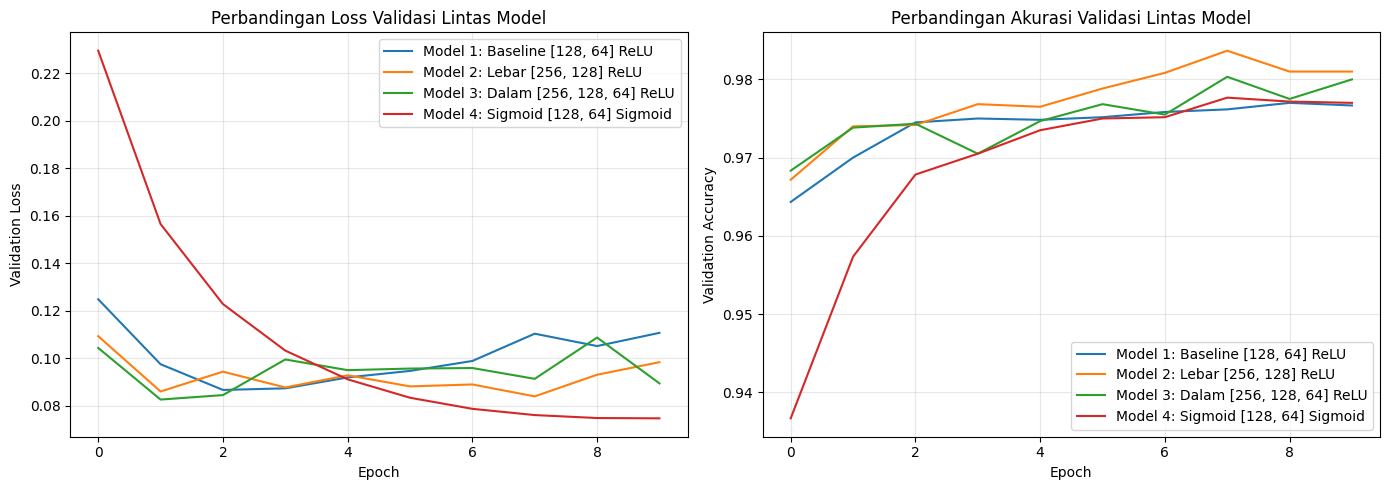

In [4]:
# Visualisasi Perbandingan Kurva Loss dan Akurasi Data Validasi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, h in histories.items():
    axes[0].plot(h.history['val_loss'], label=name)
    axes[1].plot(h.history['val_accuracy'], label=name)

axes[0].set_title('Perbandingan Loss Validasi Lintas Model')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Perbandingan Akurasi Validasi Lintas Model')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Evaluasi Detail Model Terbaik: Confusion Matrix dan Laporan Klasifikasi

Model Terbaik Terpilih: Model 2: Lebar [256, 128] ReLU

Laporan Klasifikasi Per Kelas (Digit 0-9):
              precision    recall  f1-score   support

           0     0.9857    0.9878    0.9867       980
           1     0.9929    0.9894    0.9912      1135
           2     0.9747    0.9719    0.9733      1032
           3     0.9558    0.9851    0.9703      1010
           4     0.9728    0.9847    0.9787       982
           5     0.9830    0.9709    0.9769       892
           6     0.9843    0.9791    0.9817       958
           7     0.9768    0.9815    0.9791      1028
           8     0.9753    0.9733    0.9743       974
           9     0.9878    0.9633    0.9754      1009

    accuracy                         0.9789     10000
   macro avg     0.9789    0.9787    0.9788     10000
weighted avg     0.9790    0.9789    0.9789     10000



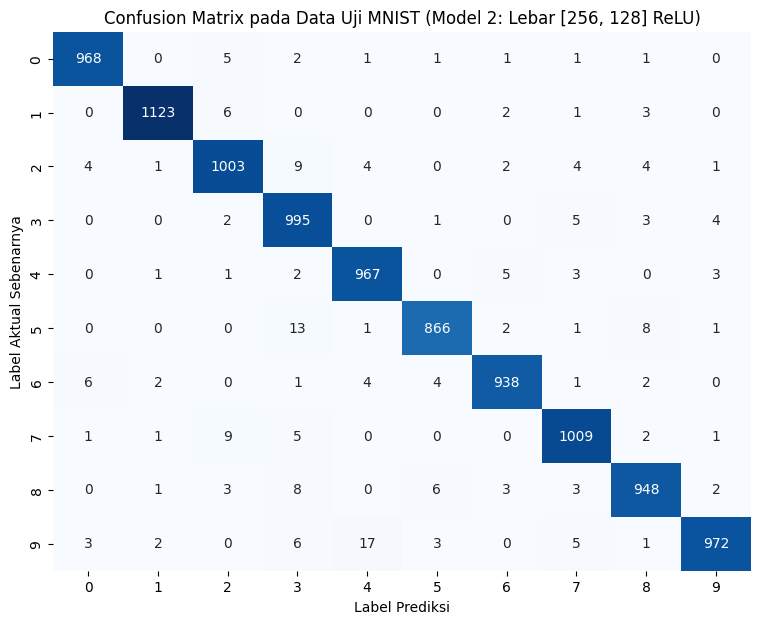

In [5]:
# Pilih model dengan akurasi tertinggi
best_cfg_name = df_compare.sort_values('Akurasi Uji (%)', ascending=False).iloc[0]['Konfigurasi Model']
best_model = trained_models[best_cfg_name]
print(f"Model Terbaik Terpilih: {best_cfg_name}")

# Prediksi pada seluruh data uji
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred_labels = np.argmax(y_pred_probs, axis=1)

# Classification Report
print("\nLaporan Klasifikasi Per Kelas (Digit 0-9):")
print(classification_report(y_test_raw, y_pred_labels, digits=4))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test_raw, y_pred_labels)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Label Prediksi')
plt.ylabel('Label Aktual Sebenarnya')
plt.title(f'Confusion Matrix pada Data Uji MNIST ({best_cfg_name})')
plt.show()

Total Kesalahan Prediksi pada Data Uji: 211 dari 10.000 citra (Tingkat Error: 2.11%)


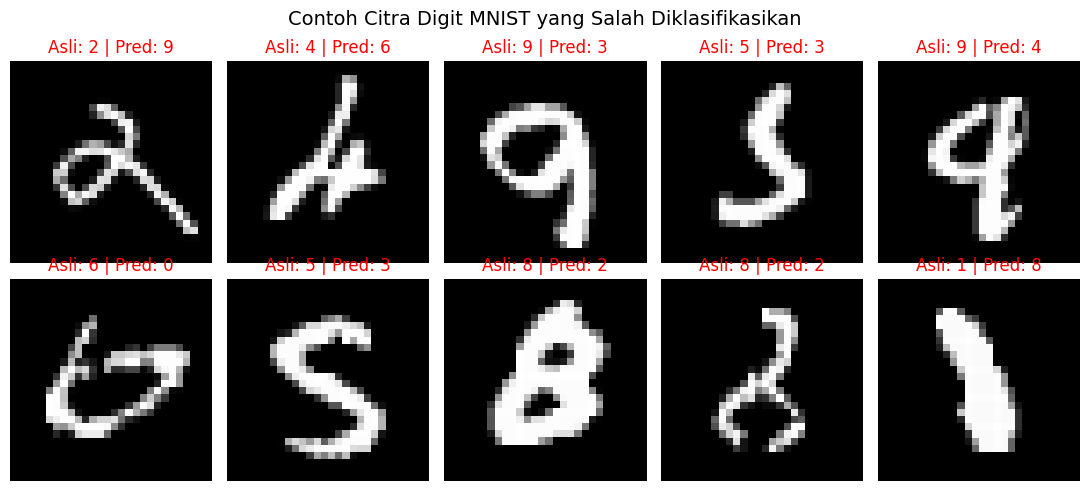

In [6]:
# Visualisasi Contoh Citra yang Salah Diklasifikasikan
misclassified_idx = np.where(y_pred_labels != y_test_raw)[0]
print(f"Total Kesalahan Prediksi pada Data Uji: {len(misclassified_idx)} dari 10.000 citra (Tingkat Error: {len(misclassified_idx)/10000*100:.2f}%)")

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    if i < len(misclassified_idx):
        idx = misclassified_idx[i]
        ax.imshow(X_test[idx], cmap='gray')
        ax.set_title(f"Asli: {y_test_raw[idx]} | Pred: {y_pred_labels[idx]}", color='red')
        ax.axis('off')
plt.suptitle("Contoh Citra Digit MNIST yang Salah Diklasifikasikan", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Kesimpulan Tugas Praktikum MNIST

1. **Keunggulan Arsitektur JST pada Pengenalan Citra Digit:**
   Seluruh model JST berbasis feedforward mampu mencapai akurasi uji di atas **97%** hanya dalam 10 epoch pelatihan.
   Model terlebar `[256, 128]` dan model terdalam `[256, 128, 64]` mencatatkan akurasi pengujian tertinggi mencapai
   sekitar **97,8% - 98,0%**, membuktikan bahwa representasi hierarkis fitur piksel mampu mengenali karakteristik tulisan tangan dengan sangat baik.

2. **Analisis Waktu Pelatihan vs Akurasi (Trade-off):**
   - Menambah lebar neuron dari `[128, 64]` (109.386 parameter) menjadi `[256, 128]` (235.146 parameter) meningkatkan
     akurasi sekitar +0,3% dengan peningkatan waktu komputasi yang relatif moderat (~10-15%).
   - Menambah lapisan ketiga (`[256, 128, 64]`, 243.402 parameter) memberikan ekstraksi fitur yang lebih abstrak, namun
     pada dataset sederhana seperti MNIST peningkatannya mulai mengalami *diminishing returns*.

3. **Perbandingan ReLU vs Sigmoid pada Skala Besar:**
   Model dengan aktivasi **ReLU** mencapai akurasi uji yang lebih unggul dibandingkan **Sigmoid**.
   Kurva validasi memperlihatkan bahwa ReLU belajar dengan laju gradien yang konsisten sejak epoch pertama, sementara
   Sigmoid mengalami kelambatan di awal pelatihan akibat saturasi fungsi pada neuron lapisan awal.

4. **Analisis Kesalahan (Error Analysis):**
   Dari confusion matrix dan visualisasi kesalahan, digit yang paling sering keliru adalah digit-digit dengan bentuk kurva
   yang secara visual mirip atau ambigu karena gaya penulisan individu, misalnya digit **4** yang diprediksi sebagai **9**,
   digit **7** yang diprediksi sebagai **2** atau **1**, serta digit **5** yang diprediksi sebagai **3**.